# 04 — Feature bank, classifier heads, and the alert measurement

Notebook 02 produced one fact that changes the plan: the fine-tuned ResNet-50 was **worse** than the
frozen-backbone baseline on held-out camera sites (test macro F1 0.6043 vs 0.6245) while its
validation score rose, i.e. it overfitted the sites it had seen. Re-running whole training rounds to
hunt for a better head would cost ~40 GPU-minutes each. This notebook therefore extracts the frozen
backbone's 2048-D features **once**, caches them, and lets every head variant be scored in seconds.

It also does the thing Phase II is marked on: it feeds the real class posteriors into the alert rule
(`src/sequence/alert.py`) and counts alerts per camera-day for per-frame alerting versus the
sequence gate. The operating configuration is pre-registered (`tier_min=3`, `min_visits=2`,
`score_threshold=0.5`); the sweep that follows it is reported as a sensitivity curve, not as a way to
pick the number after seeing the result.

In [1]:
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import transforms as T
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

ROOT = next(a for a in [Path.cwd(), *Path.cwd().parents] if (a / "data/splits").exists())
IMG_ROOT = ROOT / "data/raw/iwildcam_v2.0/train"
SPLITS_DIR = ROOT / "data/splits"
OUT = Path(os.environ.get("P11_OUT", ROOT / "outputs/logs/notebook04"))
BANK = Path(os.environ.get("P11_BANK", ROOT / "data/processed/feature_bank.npz"))
WEIGHTS = Path(os.path.expanduser("~/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth"))
sys.path.insert(0, str(ROOT / "src/vision"))
sys.path.insert(0, str(ROOT / "src/sequence"))
import wildlife as W
import alert as A

OUT.mkdir(parents=True, exist_ok=True)
BANK.parent.mkdir(parents=True, exist_ok=True)
SEED, BATCH = W.SEED, int(os.environ.get("P11_BATCH", 256))
W.set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(json.dumps({"seed": SEED, "bank": str(BANK), "out": str(OUT),
                  "images": IMG_ROOT.is_dir(), **W.hardware_note()}, indent=2))

{
  "seed": 13,
  "bank": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\data\\processed\\feature_bank.npz",
  "out": "C:\\Users\\xxshi\\Desktop\\PYTHOM\\DL_PBL\\outputs\\logs\\notebook04",
  "images": true,
  "device": "cuda",
  "torch": "2.7.1+cu118",
  "gpu": "NVIDIA GeForce RTX 3060 Laptop GPU",
  "vram_gb": 6.0
}


## 1. Feature bank (one forward pass, cached)

Evaluation transforms only — a cached feature vector must be deterministic, so augmentation lives in the
head experiments that train on pixels, not here. Float16 halves the file size; the values are
post-ReLU activations, all non-negative and well inside float16 range.

In [2]:
tables = {s: W.on_disk(pd.read_csv(SPLITS_DIR / f"{s}.csv"), IMG_ROOT) for s in ("train", "val", "test")}
class_map = pd.read_csv(SPLITS_DIR / "class_map.csv").set_index("label")["class_name"]
N_CLASSES = len(class_map)
LABELS = np.arange(N_CLASSES)

if BANK.exists():
    z = np.load(BANK)
    feats = {s: (z[f"{s}_x"].astype(np.float32), z[f"{s}_y"]) for s in ("train", "val", "test")}
    print("loaded cached bank", BANK)
else:
    tf = T.Compose([T.Resize((224, 224)), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    encoder = W.load_resnet50(WEIGHTS, n_classes=0, pretrained=True).to(DEVICE).eval()
    t0 = time.time()
    feats = {s: W.extract_features(encoder, DataLoader(W.WildlifeImages(t, IMG_ROOT, tf),
                                                       batch_size=256, num_workers=4, pin_memory=True), DEVICE)
             for s, t in tables.items()}
    np.savez_compressed(BANK, **{f"{s}_{k}": v.astype(np.float16) if k == "x" else v
                                 for s, (x, y) in feats.items() for k, v in (("x", x), ("y", y))})
    print(f"extracted and cached in {round(time.time()-t0)}s -> {BANK}")
print({s: v[0].shape for s, v in feats.items()}, "| classes:", N_CLASSES)

36060/36060 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


10234/10234 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


19928/19928 manifest images present in C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\raw\iwildcam_v2.0\train


loaded cached bank C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\data\processed\feature_bank.npz
{'train': (36060, 2048), 'val': (10234, 2048), 'test': (19928, 2048)} | classes: 13


## 2. Head variants

All arms see identical features, identical splits, identical seed; only the head differs. Two reporting
numbers are printed on purpose: macro F1 over all 13 classes, and over classes with at least 50 test
images, because one class has just 2 test images and can swing the headline by ~7 points.

In [3]:
Xtr, ytr = feats["train"]
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xval_s, Xtest_s = (scaler.transform(feats[s][0]) for s in ("train", "val", "test"))
counts = W.class_counts(tables["test"]).reindex(range(N_CLASSES), fill_value=0)
rich = np.array([l for l in LABELS if counts[l] >= 50])

proba_of = {}


def report(name, proba):
    """Every arm is scored on the same features, splits and seed; only the head differs."""
    row = {"head": name}
    for split, X in (("val", Xval_s), ("test", Xtest_s)):
        y = feats[split][1]
        yhat = proba(X).argmax(1)
        m = W.metrics(y, yhat, LABELS)
        row[f"{split}_macro_f1"] = round(m["macro_f1"], 4)
        row[f"{split}_macro_f1_rich"] = round(W.metrics(y, yhat, rich)["macro_f1"], 4)
        row[f"{split}_accuracy"] = round(m["accuracy"], 4)
    proba_of[name] = proba
    return row


def torch_head(hidden, dropout, l2, epochs=30, lr=1e-3):
    net = torch.nn.Sequential(torch.nn.Linear(2048, hidden), torch.nn.ReLU(),
                              torch.nn.Dropout(dropout), torch.nn.Linear(hidden, N_CLASSES)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=l2)
    crit = torch.nn.CrossEntropyLoss(weight=W.head_weights(tables["train"], N_CLASSES).to(DEVICE))
    xt, yt = torch.tensor(Xtr_s, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    net.train()
    for _ in range(epochs):
        perm = torch.randperm(len(xt), device=DEVICE)
        for start in range(0, len(xt), 512):
            sel = perm[start:start + 512]
            opt.zero_grad()
            crit(net(xt[sel]), yt[sel]).backward()
            opt.step()
    net.eval()

    def proba(X, n=net):
        with torch.no_grad():
            return torch.softmax(n(torch.tensor(X, device=DEVICE)), 1).cpu().numpy()
    return proba


t0 = time.time()
lr_model = LogisticRegression(max_iter=500, class_weight="balanced").fit(Xtr_s, ytr)
results = [report("logreg_balanced", lr_model.predict_proba)]
results[-1]["note"] = f"fit {round(time.time()-t0)}s"
for hidden, drop, l2, tag in ((512, 0.5, 1e-4, "mlp512_dropout_l2"), (512, 0.0, 1e-4, "mlp512_nodropout"),
                              (512, 0.5, 0.0, "mlp512_dropout_nol2"), (2048, 0.0, 1e-4, "mlp2048_nodrop")):
    t1 = time.time()
    fn = torch_head(hidden, drop, l2)
    row = report(tag, fn)
    row["note"] = f"hidden={hidden} dropout={drop} wd={l2} train {round(time.time()-t1)}s"
    results.append(row)

heads_df = pd.DataFrame(results)
heads_df

,head,val_macro_f1,val_macro_f1_rich,val_accuracy,test_macro_f1,test_macro_f1_rich,test_accuracy,note
0,logreg_balanced,0.5541,0.5372,0.6740,0.6107,0.6605,0.7343,fit 95s
1,mlp512_dropout_l2,0.5591,0.5540,0.6826,0.6407,0.6924,0.7726,hidden=512 dropout=0.5 wd=0.0001 train 7s
2,mlp512_nodropout,0.5823,0.5679,0.7122,0.6219,0.6727,0.7404,hidden=512 dropout=0.0 wd=0.0001 train 4s
3,mlp512_dropout_nol2,0.5785,0.5664,0.7113,0.6212,0.6719,0.7468,hidden=512 dropout=0.5 wd=0.0 train 5s
4,mlp2048_nodrop,0.5727,0.5609,0.6999,0.6236,0.6747,0.7535,hidden=2048 dropout=0.0 wd=0.0001 train 13s


selected on val: mlp512_nodropout | val macro F1 0.5823 | test 0.6219 (rich-class test 0.6727 )
reference points: notebook02 frozen+logreg test 0.6245, fine-tuned test 0.6043


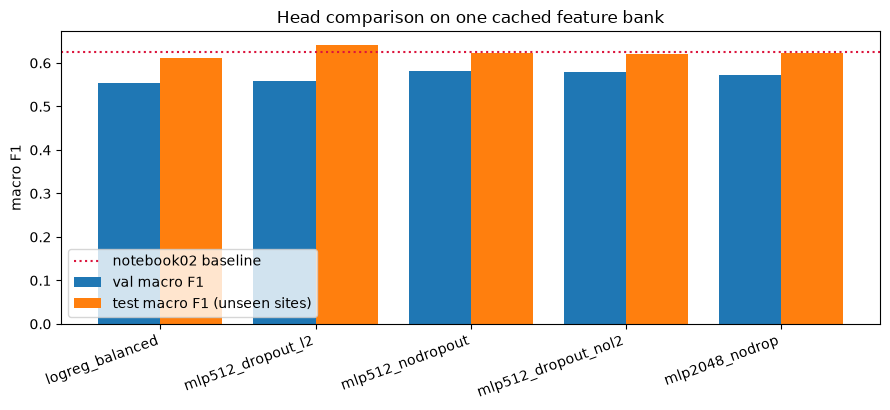

In [4]:
best = heads_df.sort_values("val_macro_f1").iloc[-1]
print("selected on val:", best["head"], "| val macro F1", best["val_macro_f1"],
      "| test", best["test_macro_f1"], "(rich-class test", best["test_macro_f1_rich"], ")")
print("reference points: notebook02 frozen+logreg test 0.6245, fine-tuned test 0.6043")
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(heads_df))
ax.bar(x - 0.2, heads_df.val_macro_f1, 0.4, label="val macro F1")
ax.bar(x + 0.2, heads_df.test_macro_f1, 0.4, label="test macro F1 (unseen sites)")
ax.set_xticks(x); ax.set_xticklabels(heads_df["head"], rotation=20, ha="right")
ax.axhline(0.6245, ls=":", color="crimson", label="notebook02 baseline")
ax.legend(); ax.set_ylabel("macro F1"); ax.set_title("Head comparison on one cached feature bank")
plt.tight_layout(); plt.savefig(OUT / "head_comparison.png", dpi=120)

## 3. The alert measurement

Per-frame alerting (what a shipped camera-trap app does by default: any detection is an incident) versus
the sequence gate, on real posteriors, counted per camera-day. Config is the pre-registered one.

In [5]:
test_proba = proba_of[best["head"]](Xtest_s)
pred_test, conf_test = test_proba.argmax(1), test_proba.max(1)
test_tbl = tables["test"].iloc[:len(pred_test)].copy()
species_of = {int(l): str(class_map[l]) for l in range(N_CLASSES)}
cfg = A.AlertConfig()

# `evidence` is what an deployed app sees (model predictions + confidence); `truth` is the same frames
# with their real labels. Alert streams are judged against truth, never against their own predictions.
evidence = A.visits_from_manifest(test_tbl, confidence=conf_test, predicted=pred_test)
truth = A.visits_from_manifest(test_tbl)
measured = A.evaluate_per_frame_vs_gated(evidence, truth, species_of, cfg)
print("pre-registered config:", cfg)
print(json.dumps(measured, indent=2))
print(f"alerts per camera-day: per-frame {measured['per_frame']['alerts_per_camera_day']} -> "
      f"gated {measured['gated']['alerts_per_camera_day']} ({measured['alerts_reduced_by']:.1%} fewer)")
print("recall of qualifying camera-days: per-frame", measured["per_frame"]["recall_of_qualifying_days"],
      "| gated", measured["gated"]["recall_of_qualifying_days"])
print("precision: per-frame", measured["per_frame"]["precision"], "| gated", measured["gated"]["precision"])

pre-registered config: AlertConfig(tier_min=3, half_life_hours=6.0, night_weight=1.5, min_visits=2, score_threshold=0.5)
{
  "camera_days": 633,
  "qualifying_camera_days": 139,
  "days_with_no_animal": 191,
  "gated": {
    "alerts": 74,
    "alerts_per_camera_day": 0.1169,
    "true_alerts": 63,
    "false_alerts": 11,
    "missed_alerts": 76,
    "precision": 0.8514,
    "recall_of_qualifying_days": 0.4532
  },
  "per_frame": {
    "alerts": 173,
    "alerts_per_camera_day": 0.2733,
    "true_alerts": 115,
    "false_alerts": 58,
    "missed_alerts": 24,
    "precision": 0.6647,
    "recall_of_qualifying_days": 0.8273
  },
  "alerts_reduced_by": 0.5723
}
alerts per camera-day: per-frame 0.2733 -> gated 0.1169 (57.2% fewer)
recall of qualifying camera-days: per-frame 0.8273 | gated 0.4532
precision: per-frame 0.6647 | gated 0.8514


In [6]:
rows = []
for tier in (2, 3, 4):
    for mv in (1, 2, 3):
        c = A.AlertConfig(tier_min=tier, min_visits=mv)
        m = A.evaluate_per_frame_vs_gated(evidence, truth, species_of, c)
        rows.append({"tier_min": tier, "min_visits": mv,
                     "qualifying_days": m["qualifying_camera_days"],
                     "gated_alerts": m["gated"]["alerts"], "gated_false": m["gated"]["false_alerts"],
                     "gated_missed": m["gated"]["missed_alerts"],
                     "gated_recall": m["gated"]["recall_of_qualifying_days"],
                     "per_frame_alerts": m["per_frame"]["alerts"],
                     "per_frame_recall": m["per_frame"]["recall_of_qualifying_days"]})
sens = pd.DataFrame(rows)
print("sensitivity of the gate to its two design parameters (reported, not used for selection):")
sens

sensitivity of the gate to its two design parameters (reported, not used for selection):


,tier_min,min_visits,qualifying_days,gated_alerts,gated_false,gated_missed,gated_recall,per_frame_alerts,per_frame_recall
0,2,1,181,165,37,53,0.7072,208,0.8343
1,2,2,181,87,6,100,0.4475,208,0.8343
2,2,3,181,58,1,124,0.3149,208,0.8343
3,3,1,139,146,47,40,0.7122,173,0.8273
4,3,2,139,74,11,76,0.4532,173,0.8273
5,3,3,139,47,1,93,0.3309,173,0.8273
6,4,1,50,62,30,18,0.6400,67,0.7200
7,4,2,50,24,5,31,0.3800,67,0.7200
8,4,3,50,8,0,42,0.1600,67,0.7200


camera-days: 633 | qualifying camera-days: 139


,rule,budget,true_alerts,false_alerts,precision,recall
0,sequence_gate,25,24,1,0.9600,0.1727
1,sequence_gate,50,49,1,0.9800,0.3525
2,sequence_gate,75,65,10,0.8667,0.4676
3,sequence_gate,100,80,20,0.8000,0.5755
4,sequence_gate,125,92,33,0.7360,0.6619
5,sequence_gate,150,101,49,0.6733,0.7266
6,volume_ranked,25,24,1,0.9600,0.1727
7,volume_ranked,50,48,2,0.9600,0.3453
8,volume_ranked,75,68,7,0.9067,0.4892
9,volume_ranked,100,79,21,0.7900,0.5683


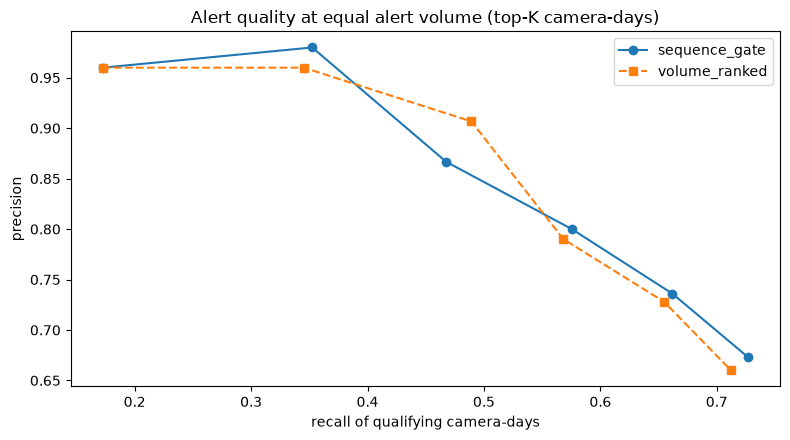

In [7]:
# Budget-matched comparison: rank camera-days by the gate score vs by raw qualifying-frame volume and
# alert the top K of each. Same alert workload, so precision/recall are comparable.
curve = A.budget_curve(evidence, truth, species_of, cfg, budgets=(25, 50, 75, 100, 125, 150))
print("camera-days:", measured["camera_days"], "| qualifying camera-days:", measured["qualifying_camera_days"])
fig, ax = plt.subplots(figsize=(8, 4.5))
for rule, marker in (("sequence_gate", "o-"), ("volume_ranked", "s--")):
    sub = curve[curve.rule == rule]
    ax.plot(sub.recall, sub.precision, marker, label=rule)
ax.set_xlabel("recall of qualifying camera-days"); ax.set_ylabel("precision")
ax.set_title("Alert quality at equal alert volume (top-K camera-days)")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "alert_budget_curve.png", dpi=120)
curve

## 4. What this changes

Record the outcome honestly, including the negative one: notebook 02's fine-tune lost 0.0202 macro F1 to
the frozen backbone on unseen camera sites. If the arms here also fail to clear that baseline, the
Phase I model *is* the baseline, and the innovation moves entirely to the alert gate, which is measured
in false alerts rather than in macro F1. That is a defensible product decision: on a fixed backbone, an
operator can still be given fewer, better alerts, and that is what the deployment cares about.

In [8]:
run = {"run_utc": pd.Timestamp.now(tz="UTC").isoformat(), "experiment": "notebook04_heads_and_alert_gate",
       "seed": SEED, "feature_bank": str(BANK), "bank_mb": round(BANK.stat().st_size / 2**20, 1),
       "heads": json.loads(heads_df.to_json(orient="records")), "selected_on_val": best["head"],
       "alert_cfg": {"tier_min": cfg.tier_min, "half_life_hours": cfg.half_life_hours,
                      "night_weight": cfg.night_weight, "min_visits": cfg.min_visits,
                      "score_threshold": cfg.score_threshold},
       "gate": measured, "hardware": W.hardware_note()}
with open(OUT / "experiment_log.jsonl", "a", encoding="utf-8") as fh:
    fh.write(json.dumps(run) + "\n")
sens.to_csv(OUT / "alert_sensitivity.csv", index=False)
heads_df.to_csv(OUT / "head_comparison.csv", index=False)
print("logged to", OUT)

logged to C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\logs\notebook04


In [9]:
# Persist a head the prototype app can load without retraining. Only the logistic pipeline is saved:
# a torch MLP head would have to be stored as a module (a closure is not picklable), and its advantage
# over this head is not a claim worth making yet (0.6219 vs 0.6245 across different numeric pipelines).
import joblib

CKPT_DIR = ROOT / "outputs/checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
bundle = {"pipeline": lr_model, "scaler": scaler, "head_name": "logreg_balanced",
          "val_selected_head": best["head"],
          "class_names": [str(class_map[l]) for l in range(N_CLASSES)],
          "weights_path": str(WEIGHTS), "feature_dim": int(Xtr.shape[1]), "seed": SEED,
          "logreg_test_macro_f1": float(heads_df.set_index("head").loc["logreg_balanced", "test_macro_f1"])}
joblib.dump(bundle, CKPT_DIR / "species_head.joblib")
print("saved", CKPT_DIR / "species_head.joblib", "| heads:", bundle["head_name"],
      "| val-selected:", bundle["val_selected_head"])

saved C:\Users\xxshi\Desktop\PYTHOM\DL_PBL\outputs\checkpoints\species_head.joblib | heads: logreg_balanced | val-selected: mlp512_nodropout
